# Paprastosios pušies projektas
## 3 dalis. Baseline modelis, RandomForest, metrikos ir SHAP

Šiame sąsiuvinyje atliekame du privalomus eksperimentus ir juos palyginame:
1. **Baseline (bazinis):** paprastas metodas (dažniausios klasės prognozė ir LogisticRegression).
2. **Proposed (patobulintas):** RandomForest su hiperparametrų paieška.

Tada paaiškiname, **kodėl** modelis taip sprendžia (svarba ir SHAP).

**Prieš pradedant:** turi būti 2 dalies failas `pusis_su_dirvozemiu.csv`.
Paleiskite langelius iš eilės (Shift + Enter), nuo viršaus iki apačios.

### 1. Bibliotekos

In [1]:
# Jei trūksta bibliotekos, atkomentuokite eilutę (pašalinkite #) ir paleiskite vieną kartą:
# %pip install scikit-learn matplotlib pandas

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

print("Bibliotekos įkeltos")

Bibliotekos įkeltos


### 2. Duomenų įkėlimas

In [6]:
rasti = sorted(Path.home().rglob("pusis_su_dirvozemiu.csv"), key=lambda f: f.stat().st_mtime, reverse=True)
if not rasti:
    raise FileNotFoundError("Nerastas pusis_su_dirvozemiu.csv. Pirmiausia paleiskite 2 dalies sąsiuvinį.")
print("Rastas failas:", rasti[0])

df = pd.read_csv(rasti[0])
print("Eilučių:", len(df))
print(df["pusis"].value_counts())
df.head()

Rastas failas: C:\Users\linak\pusis_su_dirvozemiu.csv
Eilučių: 1154
pusis
0    616
1    538
Name: count, dtype: int64


,lat,lon,pusis,phh2o_0-5cm,phh2o_5-15cm,phh2o_15-30cm,sand_0-5cm,sand_5-15cm,sand_15-30cm,clay_0-5cm,clay_5-15cm,clay_15-30cm,soc_0-5cm,soc_5-15cm,soc_15-30cm
0,54.689197,25.233472,1,5.6,5.7,5.7,53.8,53.7,54.1,17.7,17.1,17.1,94.7,60.0,74.6
1,55.764327,21.085213,1,5.7,5.8,5.9,59.7,60.2,59.0,12.4,12.2,12.6,102.3,76.0,44.9
2,55.508824,25.085028,1,5.3,5.4,5.5,51.8,50.7,46.9,16.4,16.6,20.5,104.7,74.4,25.6
3,54.721744,25.225768,1,6.5,6.6,6.6,58.7,60.5,59.8,14.0,12.9,14.0,85.2,32.1,50.5
4,55.730133,21.115080,1,5.5,5.5,5.6,61.1,60.9,59.5,14.0,14.3,14.6,121.6,92.5,56.0


### 3. Požymiai ir tikslas
- **Tikslas (`y`):** `pusis` (1 = pušis yra, 0 = pušies nėra).
- **Požymiai (`X`):** tik dirvožemio savybės (pH, smėlis, molis, organinė anglis, trys gyliai). Koordinačių modeliui **neduodame**, kad jis nemokytųsi „šioje vietoje pušis, nes čia jau buvo“, o mokytųsi iš dirvožemio.

### Kaip dalijame duomenis į mokymo ir testavimo dalis
Kaimyniniai taškai turi labai panašų dirvožemį. Jei dalintume atsitiktinai, modelis „nusirašytų“ atsakymą iš šalia esančių taškų ir rezultatas atrodytų geresnis nei yra. Todėl Lietuvą padalijame į stačiakampius (apie 50 × 30 km) ir **ištisus stačiakampius** skiriame testavimui. Tai vadinama erdviniu skaidymu.

In [7]:
pozymiai = [c for c in df.columns if c.startswith(("phh2o_", "sand_", "clay_", "soc_"))]
print("Požymiai:", pozymiai)

X = df[pozymiai]
y = df["pusis"]

# Erdviniai stačiakampiai (0,5 laipsnio): kiekvienas taškas priklauso vienam
grupes = (np.floor(df["lat"] * 2).astype(int).astype(str) + "_" +
          np.floor(df["lon"] * 2).astype(int).astype(str))
grupes = pd.factorize(grupes)[0]
print("Stačiakampių skaičius:", grupes.max() + 1)

dalintojas = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
mokymo_idx, testo_idx = next(dalintojas.split(X, y, groups=grupes))

X_train, X_test = X.iloc[mokymo_idx], X.iloc[testo_idx]
y_train, y_test = y.iloc[mokymo_idx], y.iloc[testo_idx]
grupes_train = grupes[mokymo_idx]

print("Mokymui:", len(X_train), "| Testavimui:", len(X_test))
print("Testavimo klasės:", y_test.value_counts().to_dict())

Požymiai: ['phh2o_0-5cm', 'phh2o_5-15cm', 'phh2o_15-30cm', 'sand_0-5cm', 'sand_5-15cm', 'sand_15-30cm', 'clay_0-5cm', 'clay_5-15cm', 'clay_15-30cm', 'soc_0-5cm', 'soc_5-15cm', 'soc_15-30cm']
Stačiakampių skaičius: 51
Mokymui: 924 | Testavimui: 230
Testavimo klasės: {0: 138, 1: 92}


### 4. Metrikų funkcija
Skaičiuojame tas metrikas, kurių reikalauja dėstytojas: Accuracy, Precision, Recall ir F1 (papildomai ROC AUC).

In [8]:
def ivertinti(modelis, X_t, y_t):
    pred = modelis.predict(X_t)
    prob = modelis.predict_proba(X_t)[:, 1]
    return {
        "Accuracy": accuracy_score(y_t, pred),
        "Precision": precision_score(y_t, pred, zero_division=0),
        "Recall": recall_score(y_t, pred, zero_division=0),
        "F1": f1_score(y_t, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_t, prob),
    }

### 5. Baseline eksperimentas
Du paprasti modeliai:
- **Dummy:** visada spėja dažniausią klasę. Tai „atsitiktinio“ lygio pamatas.
- **LogisticRegression:** paprasta tiesinė klasifikacija.

In [9]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

rezultatai = {
    "Baseline: Dummy": ivertinti(dummy, X_test, y_test),
    "Baseline: LogisticRegression": ivertinti(logreg, X_test, y_test),
}
pd.DataFrame(rezultatai).T.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Baseline: Dummy,0.60,0.000,0.000,0.000,0.500
Baseline: LogisticRegression,0.63,0.531,0.652,0.585,0.697


### 6. Proposed eksperimentas: RandomForest
Vienas ar du paprasti nustatymai (hiperparametrai) parenkami automatiškai: bandome kelis variantus ir renkamės geriausią pagal F1. Parinkimui naudojame tik mokymo duomenis ir vėl dalijame **pagal stačiakampius**.

Tai gali užtrukti nuo kelių sekundžių iki minutės.

In [10]:
parametrai = {
    "n_estimators": [200, 400],
    "max_depth": [None, 6, 12],
    "min_samples_leaf": [1, 5],
}

paieska = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    parametrai,
    scoring="f1",
    cv=GroupKFold(n_splits=5),
    n_jobs=-1,
)
paieska.fit(X_train, y_train, groups=grupes_train)

rf = paieska.best_estimator_
print("Geriausi parametrai:", paieska.best_params_)
print("F1 mokymo kryžminėje patikroje:", round(paieska.best_score_, 3))

rezultatai["Proposed: RandomForest"] = ivertinti(rf, X_test, y_test)

Geriausi parametrai: {'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 200}
F1 mokymo kryžminėje patikroje: 0.635


### 7. Lyginamoji lentelė (tai reikia įkelti į ataskaitą)
Visi modeliai vertinami **tuose pačiuose testavimo duomenyse**, kurių modelis mokymo metu nematė.

In [11]:
lentele = pd.DataFrame(rezultatai).T.round(3)
lentele.to_csv("metrikos.csv")
lentele

,Accuracy,Precision,Recall,F1,ROC AUC
Baseline: Dummy,0.600,0.000,0.000,0.000,0.500
Baseline: LogisticRegression,0.630,0.531,0.652,0.585,0.697
Proposed: RandomForest,0.657,0.561,0.652,0.603,0.709


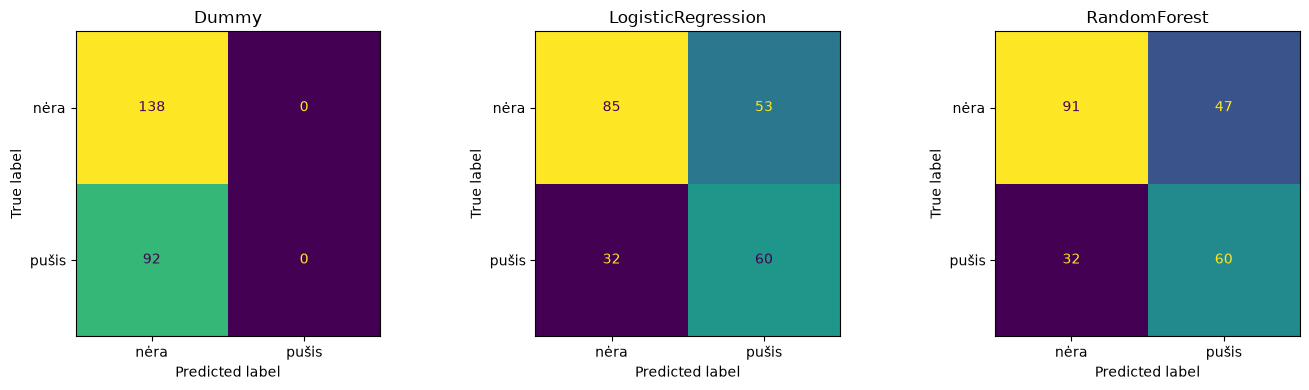

In [12]:
# Konfuzijos matricos
fig, asys = plt.subplots(1, 3, figsize=(14, 4))
modeliai = [("Dummy", dummy), ("LogisticRegression", logreg), ("RandomForest", rf)]
for ax, (pav, m) in zip(asys, modeliai):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["nėra", "pušis"])
    ax.set_title(pav)
plt.tight_layout()
plt.savefig("konfuzijos_matricos.png", dpi=150)
plt.show()

### 8. Ar pasiektas reikalavimas?
Dėstytojo kriterijus: bent **0,70 F1** arba **80 % tikslumas**. Žemiau patikrinama automatiškai.

In [13]:
f1_rf = rezultatai["Proposed: RandomForest"]["F1"]
acc_rf = rezultatai["Proposed: RandomForest"]["Accuracy"]
print(f"RandomForest: F1 = {f1_rf:.3f}, Accuracy = {acc_rf:.3f}")
print("F1 ≥ 0,70:", "TAIP" if f1_rf >= 0.70 else "NE")
print("Accuracy ≥ 0,80:", "TAIP" if acc_rf >= 0.80 else "NE")

RandomForest: F1 = 0.603, Accuracy = 0.657
F1 ≥ 0,70: NE
Accuracy ≥ 0,80: NE


**Svarbu:** jei rezultatas bus mažesnis nei 0,70, tai **nereiškia, kad darbas blogas**. Pušis Lietuvoje auga labai įvairiose vietose, o neigiami pavyzdžiai yra atsitiktiniai taškai (kuriuose pušis irgi gali augti), todėl riba tarp klasių yra neryški. Ataskaitoje sąžiningai pateikite gautus skaičius ir paaiškinkite priežastis skyriuje „Ribotumai“. Taip pat aptarkite, ar Proposed pranoksta Baseline.

### 9. Kurie požymiai svarbiausi?
**Permutation importance** (permaišymo svarba) rodo, kiek modelio tikslumas sumažėja, kai vieno požymio reikšmės sumaišomos. Jis skaičiuojamas testavimo duomenyse ir veikia su bet kokiu modeliu.

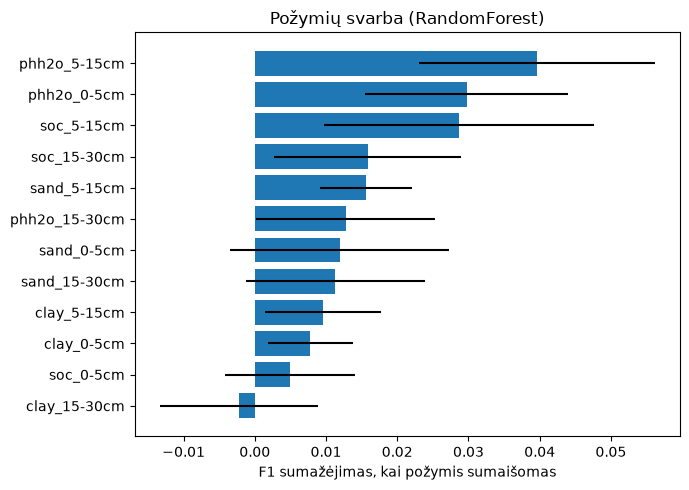

,pozymis,svarba,paklaida
1,phh2o_5-15cm,0.040,0.017
0,phh2o_0-5cm,0.030,0.014
10,soc_5-15cm,0.029,0.019
11,soc_15-30cm,0.016,0.013
4,sand_5-15cm,0.016,0.006


In [14]:
svarba = permutation_importance(rf, X_test, y_test, scoring="f1",
                                n_repeats=20, random_state=42, n_jobs=-1)

svarba_df = (pd.DataFrame({"pozymis": pozymiai,
                           "svarba": svarba.importances_mean,
                           "paklaida": svarba.importances_std})
             .sort_values("svarba"))

plt.figure(figsize=(7, 5))
plt.barh(svarba_df["pozymis"], svarba_df["svarba"], xerr=svarba_df["paklaida"])
plt.xlabel("F1 sumažėjimas, kai požymis sumaišomas")
plt.title("Požymių svarba (RandomForest)")
plt.tight_layout()
plt.savefig("pozymiu_svarba.png", dpi=150)
plt.show()

svarba_df.sort_values("svarba", ascending=False).head(5).round(3)

### 10. SHAP (paaiškinamumas)
SHAP parodo, **kaip kiekvienas požymis paveikė konkretų modelio sprendimą**: ar didelė smėlio dalis didino, ar mažino pušies tikimybę.

Jei biblioteka `shap` neįdiegta, atkomentuokite `%pip install shap` kitame langelyje, paleiskite jį, perkraukite kernelį (**Kernel → Restart Kernel**) ir paleiskite visus langelius iš pradžių.

In [17]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   --------------------------- ------------ 524.3/751.9 kB 1.6 MB/s eta 0:00:01
   ---------------------------------------- 751.9/751.9 kB 1.7 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


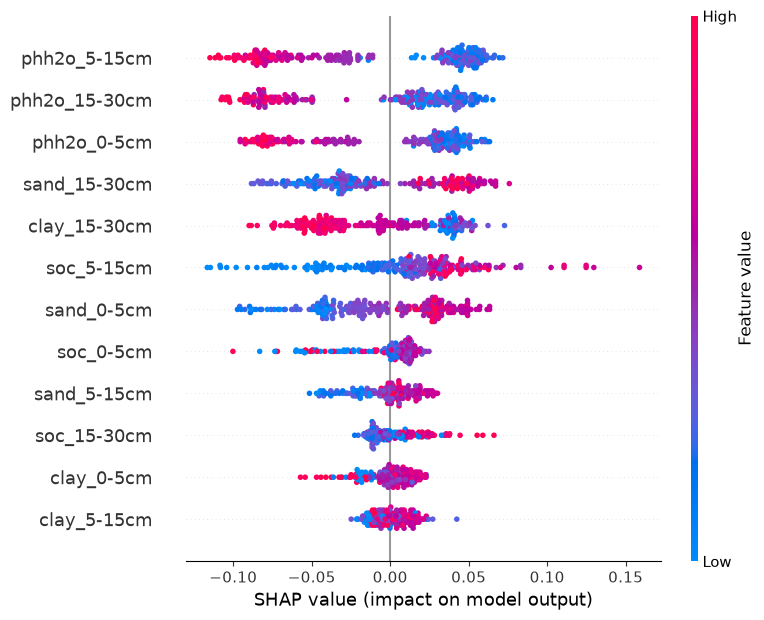

In [18]:
try:
    import shap

    aiskintojas = shap.TreeExplainer(rf)
    sv = aiskintojas.shap_values(X_test)

    # Skirtingos shap versijos grąžina skirtingos formos rezultatą; imame klasę "pušis" (1)
    if isinstance(sv, list):
        sv_pusis = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv_pusis = sv[:, :, 1]
    else:
        sv_pusis = sv

    shap.summary_plot(sv_pusis, X_test, show=False)
    plt.tight_layout()
    plt.savefig("shap_santrauka.png", dpi=150, bbox_inches="tight")
    plt.show()
except ImportError:
    print("Biblioteka shap neįdiegta. Atkomentuokite ankstesnį langelį ir paleiskite.")
except Exception as klaida:
    print("SHAP grafiko sukurti nepavyko:", klaida)
    print("Ataskaitoje galite naudoti ir permaišymo svarbos grafiką (9 žingsnis).")

**Kaip skaityti SHAP grafiką:** kiekviena eilutė yra požymis (svarbiausi viršuje), kiekvienas taškas yra viena vieta. Taškas dešinėje reiškia, kad požymis **padidino** pušies tikimybę, kairėje, kad sumažino. Spalva rodo požymio reikšmę (raudona didelė, mėlyna maža). Pvz., jei raudoni smėlio taškai yra dešinėje, tai reiškia, kad daugiau smėlio didina pušies tikimybę, o tai atitinka pušies ekologiją.

## Ką užrašyti ataskaitoje
- **Eksperimentai:** Baseline (Dummy, LogisticRegression) ir Proposed (RandomForest). Pateikite lentelę iš 7 žingsnio (`metrikos.csv`).
- **Skaidymas:** erdvinis, ištisi stačiakampiai testavimui (paaiškinkite, kodėl).
- **Konfuzijos matricos:** `konfuzijos_matricos.png`.
- **Paaiškinamumas:** `pozymiu_svarba.png` ir `shap_santrauka.png`. Ar svarbiausi požymiai atitinka pušies ekologiją (smėlis, rūgštumas, drėgnumas)?
- **Ribotumai:** pseudo-neigiami pavyzdžiai, apvalintos koordinatės, GBIF šališkumas (stebėjimai prie kelių), pušis galėjo būti pasodinta, SoilGrids yra modeliuoti duomenys (250 m).
- **Dar reikia:** `requirements.txt` (bibliotekų sąrašas), `README.md` ir GitHub nuoroda su sąsiuvinių kodu.